In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [30]:
sns.set_theme(style="whitegrid")

In [31]:
rng = np.random.default_rng(42)
print(rng)

Generator(PCG64)


In [4]:
n = 200
df = pd.DataFrame({
    "student_id": np.arange(1, n + 1),
    "gender": rng.choice(["Male", "Female"], n),
    "section": rng.choice(["A", "B", "C"], n),
    "study_hours": rng.normal(5, 1.5, n).round(1).clip(0, 10)
})
print(df.head())

   student_id  gender section  study_hours
0           1    Male       B          6.0
1           2  Female       C          4.4
2           3  Female       B          5.0
3           4    Male       C          4.8
4           5    Male       B          5.5


In [5]:
df["math"] = (
    40 + 6 * df["study_hours"] + rng.normal(0, 8, n)
).clip(0, 100).round()
df["science"] = (
    35 + 6.5 * df["study_hours"] + rng.normal(0, 9, n)
).clip(0, 100).round()
df["english"] = (
    50 + 3 * df["study_hours"] + rng.normal(0, 10, n)
).clip(0, 100).round()

In [6]:
print(df.head())

   student_id  gender section  study_hours  math  science  english
0           1    Male       B          6.0  82.0     69.0     78.0
1           2  Female       C          4.4  68.0     71.0     74.0
2           3  Female       B          5.0  74.0     70.0     75.0
3           4    Male       C          4.8  63.0     50.0     65.0
4           5    Male       B          5.5  72.0     75.0     58.0


In [7]:
# shape
print(df.shape)

(200, 7)


In [8]:
# information
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   student_id   200 non-null    int64  
 1   gender       200 non-null    str    
 2   section      200 non-null    str    
 3   study_hours  200 non-null    float64
 4   math         200 non-null    float64
 5   science      200 non-null    float64
 6   english      200 non-null    float64
dtypes: float64(4), int64(1), str(2)
memory usage: 12.2 KB
None


In [9]:
# describe
print(df.describe())

       student_id  study_hours        math     science     english
count  200.000000   200.000000  200.000000  200.000000  200.000000
mean   100.500000     5.028000   69.605000   67.165000   64.815000
std     57.879185     1.528923   12.298996   13.181294   10.408287
min      1.000000     1.200000   36.000000   23.000000   35.000000
25%     50.750000     4.000000   61.750000   57.000000   58.000000
50%    100.500000     5.100000   69.000000   67.000000   65.000000
75%    150.250000     6.000000   78.000000   76.000000   72.000000
max    200.000000     9.400000  100.000000   99.000000   92.000000


In [10]:
df.loc[rng.choice(n,10,replace=False),"math"] = np.nan
df.loc[rng.choice(n,8,replace=False),"science"] = np.nan

In [11]:
# missing values
print(df.isna().sum())

student_id      0
gender          0
section         0
study_hours     0
math           10
science         8
english         0
dtype: int64


In [12]:
df["math"] = df["math"].fillna(df["math"].median())
df["science"] = df["science"].fillna(df["science"].median())
df["english"] = df["english"].fillna(df["english"].median())

In [13]:
print(df.isna().sum())

student_id     0
gender         0
section        0
study_hours    0
math           0
science        0
english        0
dtype: int64


In [14]:
print("Total Missing Values:-", df.isna().sum().sum())

Total Missing Values:- 0


In [15]:
df["total"] = df[["math", "science", "english"]].sum(axis=1)

In [16]:
df["percentage"] = (df["total"] / 300 * 100).round(1)

In [17]:
df["grade"] = pd.cut(df["percentage"],bins=[0, 40, 60, 75, 90, 100],labels=["F", "C", "B", "A", "A+"],include_lowest=True)

In [18]:
print(df.head())

   student_id  gender section  study_hours  math  science  english  total  \
0           1    Male       B          6.0  82.0     69.0     78.0  229.0   
1           2  Female       C          4.4  68.0     71.0     74.0  213.0   
2           3  Female       B          5.0  74.0     70.0     75.0  219.0   
3           4    Male       C          4.8  63.0     50.0     65.0  178.0   
4           5    Male       B          5.5  72.0     75.0     58.0  205.0   

   percentage grade  
0        76.3     A  
1        71.0     B  
2        73.0     B  
3        59.3     C  
4        68.3     B  


In [19]:
section_analysis = df.groupby("section")[["math", "science", "english", "percentage"]].mean().round(1)
print(section_analysis)

         math  science  english  percentage
section                                    
A        68.5     67.0     64.7        66.7
B        69.6     66.5     64.1        66.7
C        70.5     67.8     65.7        68.0


In [20]:
gender_analysis = df.groupby("gender")["percentage"].agg(["mean", "median", "std"]).round(2)
print(gender_analysis)

         mean  median   std
gender                     
Female  66.82    66.7  9.35
Male    67.42    67.0  8.27


In [21]:
correlation = np.corrcoef(df["study_hours"],df["percentage"])[0, 1]
print("Correlation:", round(correlation, 3))

Correlation: 0.793


## ***Data Visualization***

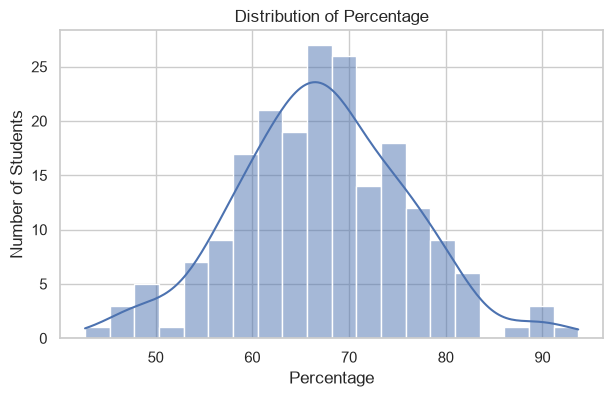

In [22]:
# Histogram plot
plt.figure(figsize=(7,4))
sns.histplot(data=df,x="percentage",bins=20,kde=True)
plt.title("Distribution of Percentage")
plt.xlabel("Percentage")
plt.ylabel("Number of Students")
plt.show()

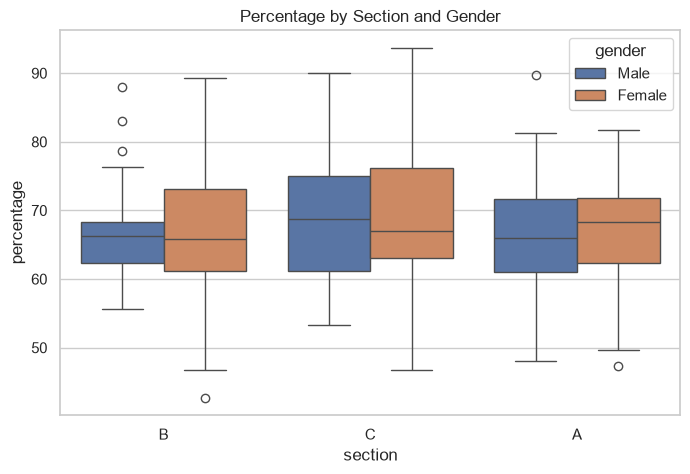

In [23]:
# Box plot
plt.figure(figsize=(8,5))
sns.boxplot(data=df,x="section",y="percentage",hue="gender")
plt.title("Percentage by Section and Gender")
plt.show()

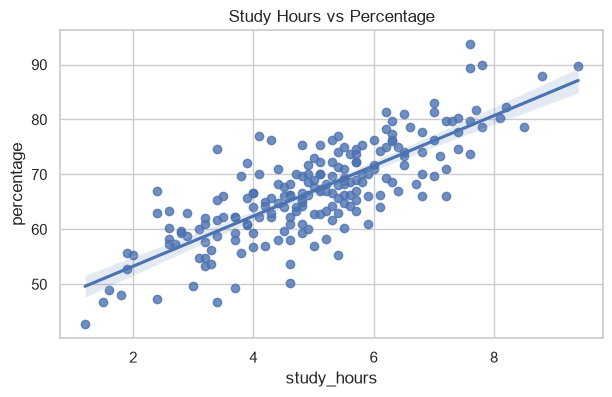

In [24]:
# Regression plot
plt.figure(figsize=(7,4))
sns.regplot(data=df,x="study_hours",y="percentage")
plt.title("Study Hours vs Percentage")
plt.show()

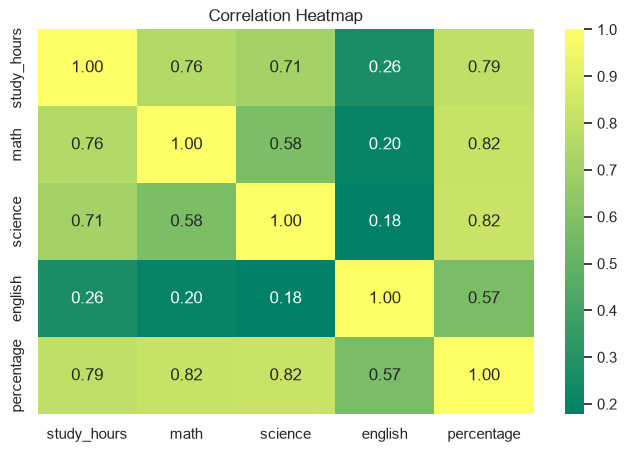

In [25]:
# Heat-map
plt.figure(figsize=(8,5))
sns.heatmap(df[["study_hours", "math", "science", "english", "percentage"]].corr(),annot=True,cmap="summer",fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

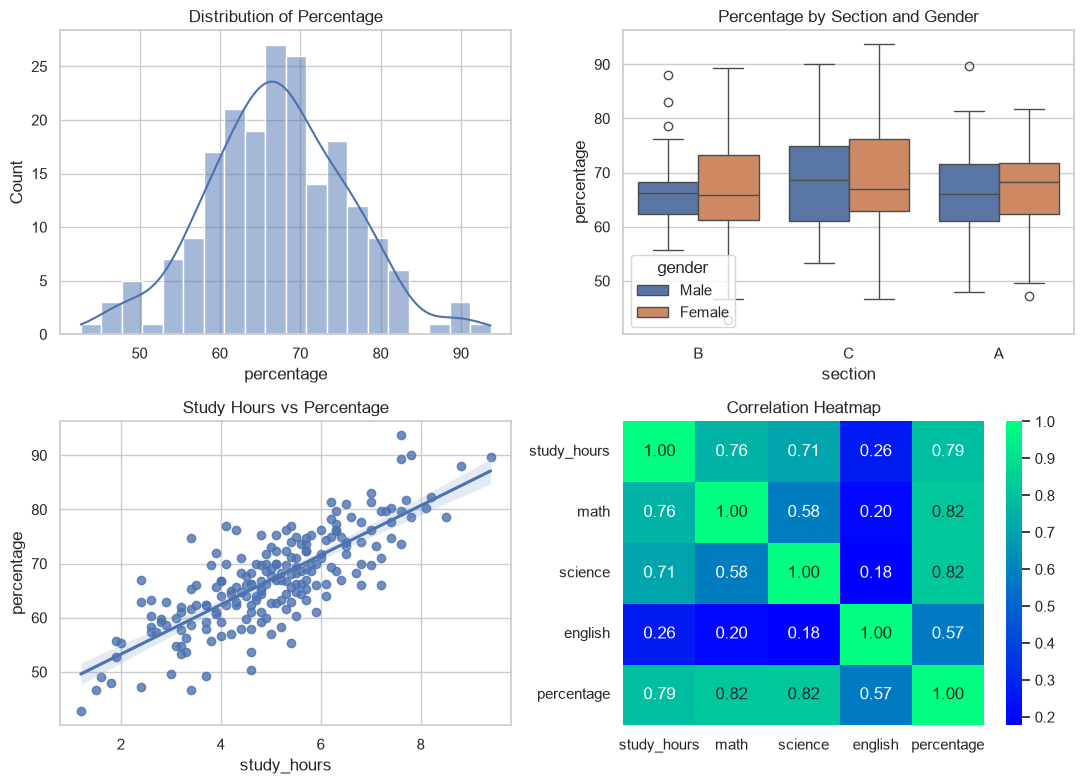

In [26]:
fig, axes = plt.subplots(2,2,figsize=(11,8))
sns.histplot(df["percentage"],bins=20,kde=True,ax=axes[0,0])
axes[0,0].set_title("Distribution of Percentage")
sns.boxplot(data=df,x="section",y="percentage",hue="gender",ax=axes[0,1])
axes[0,1].set_title("Percentage by Section and Gender")
sns.regplot(data=df,x="study_hours",y="percentage",ax=axes[1,0])
axes[1,0].set_title("Study Hours vs Percentage")
sns.heatmap(df[["study_hours","math","science","english","percentage"]].corr(),annot=True,cmap="winter",fmt=".2f",ax=axes[1,1])
axes[1,1].set_title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("task1_output.png",dpi=150)
plt.show()

In [27]:
df.to_csv("student_performance_analysis.csv",index=False)
print(df.head())

   student_id  gender section  study_hours  math  science  english  total  \
0           1    Male       B          6.0  82.0     69.0     78.0  229.0   
1           2  Female       C          4.4  68.0     71.0     74.0  213.0   
2           3  Female       B          5.0  74.0     70.0     75.0  219.0   
3           4    Male       C          4.8  63.0     50.0     65.0  178.0   
4           5    Male       B          5.5  72.0     75.0     58.0  205.0   

   percentage grade  
0        76.3     A  
1        71.0     B  
2        73.0     B  
3        59.3     C  
4        68.3     B  


In [28]:
import os
print(os.getcwd())

C:\Users\Ks\Revision_Python\DSML_7pm\Task
